## Environment Setup and Data Acquisition

In [ ]:
# Download MNIST

import urllib.request

url = "http://www.di.ens.fr/~lelarge/MNIST.tar.gz" #link of MNIST data
filename = "MNIST.tar.gz"

urllib.request.urlretrieve(url, filename)

print("Download complete:", filename)

Download complete: MNIST.tar.gz


In [6]:
# Extract Data

import tarfile

with tarfile.open("MNIST.tar.gz", "r:gz") as tar:
    tar.extractall(".")

print("Extraction complete!")

C:\Users\elhan\AppData\Local\Temp\ipykernel_24188\4145537719.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(".")


Extraction complete!


In [ ]:
import torch
import torch.nn as nn

procpath = ".\\MNIST\\processed\\" # path of data

data_train = torch.load(procpath + "training.pt")
data_test = torch.load(procpath + "test.pt")

print(data_train[0].shape)
print(data_test[0].shape)

torch.Size([60000, 28, 28])
torch.Size([10000, 28, 28])


## Data Preprocessing

In [ ]:
# The one-Hot Encoder

N = 10

targets = data_train[1][:N]

one_hot_encoder = nn.functional.one_hot(
    targets,
    num_classes=10 # 10 digits
)

for target, one_hot in zip(targets, one_hot_encoder):
    print(f"Target: {target.item()} -> {one_hot.tolist()}") # print normal digit and one hot encoder

Target: 5 -> [0, 0, 0, 0, 0, 1, 0, 0, 0, 0]
Target: 0 -> [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Target: 4 -> [0, 0, 0, 0, 1, 0, 0, 0, 0, 0]
Target: 1 -> [0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
Target: 9 -> [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
Target: 2 -> [0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
Target: 1 -> [0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
Target: 3 -> [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
Target: 1 -> [0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
Target: 4 -> [0, 0, 0, 0, 1, 0, 0, 0, 0, 0]


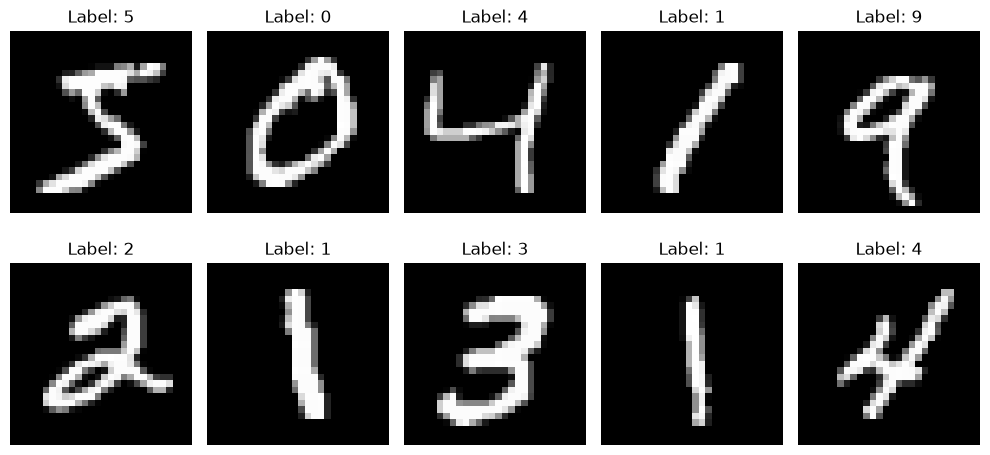

In [ ]:
# Show Data

import matplotlib.pyplot as plt

N = 10

images = data_train[0]
labels = data_train[1]

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for ax, digit, label in zip(axes.flat, images[:N], labels[:N]):
    ax.imshow(digit, cmap="gray")
    ax.set_title(f"Label: {label.item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Flattening Input Data

images_flat = images.view(-1, 28**2) #flatten labels of digits

print(images.shape)
print(images_flat.shape)

torch.Size([60000, 28, 28])
torch.Size([60000, 784])


## Creating the Dataset and DataLoader

In [ ]:
# PyTorch Dataset Object

from torch.utils.data import Dataset

class MNISTDataset(Dataset):
    def __init__(self, digits, labels):
        super().__init__()
        self.digits = digits / 255.0 # normolize
        self.labels = labels

    def __getitem__(self, index):
        digit = self.digits[index] # get digit according to index
        label = self.labels[index] # get lebal according to index
        return digit, label

    def __len__(self):
        return self.labels.shape[0] # return length of digits

In [ ]:
# Load data
train_dataset = MNISTDataset(data_train[0], data_train[1]) # train data loader
test_dataset = MNISTDataset(data_test[0], data_test[1]) # test data loader

print(len(train_dataset))
print(len(test_dataset))

60000
10000


In [ ]:
# PyTorch DataLoader Object

from torch.utils.data import DataLoader

batch_size = 64 #64 batch is optimal for my CPU

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size, 
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False # No need to shuffle train data
)

## Model Architecture and Loss

In [43]:
# Neural Network Formulation

class MLP(nn.Module):
    def __init__(self, d_in=784, widths=[100, 50], d_out=10, act=nn.ReLU):
        super().__init__()

        layers = [nn.Linear(d_in, widths[0]), act()]

        for i in range(len(widths) - 1):
            layers += [nn.Linear(widths[i], widths[i+1]), act()]

        layers += [nn.Linear(widths[-1], d_out)]

        self.net = nn.Sequential(*layers)

    def forward(self, X):
        X = X.view(-1, 28**2)
        return self.net(X)

In [ ]:
# Check model

model = MLP() 

print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=100, bias=True)
    (1): ReLU()
    (2): Linear(in_features=100, out_features=50, bias=True)
    (3): ReLU()
    (4): Linear(in_features=50, out_features=10, bias=True)
  )
)


In [ ]:
#Cross Entropy Loss

loss = nn.CrossEntropyLoss() # Loss formulation

In [52]:
iterator_train = iter(train_loader)

digits, labels = next(iterator_train)

outputs = model(digits)

loss_value = loss(outputs, labels)

print("Loss:", loss_value.item())

Loss: 2.308196544647217


## The Training Loop with Validation

In [53]:
# Optimizer
opt = torch.optim.SGD(model.parameters(), lr=0.01)

# Number of epochs
epochs = 20

train_losses = []
val_losses = []

for epoch in range(epochs):

    # Training
    model.train()
    train_loss = 0

    for digits, labels in train_loader:
        opt.zero_grad()

        outputs = model(digits)
        loss_value = loss(outputs, labels)

        loss_value.backward()
        opt.step()

        train_loss += loss_value.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for digits, labels in test_loader:
            outputs = model(digits)
            loss_value = loss(outputs, labels)

            val_loss += loss_value.item()

    val_loss /= len(test_loader)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"- Train Loss: {train_loss:.4f} "
        f"- Validation Loss: {val_loss:.4f}"
    )

Epoch 1/20 - Train Loss: 1.8361 - Validation Loss: 0.9143
Epoch 2/20 - Train Loss: 0.6168 - Validation Loss: 0.4481
Epoch 3/20 - Train Loss: 0.4155 - Validation Loss: 0.3595
Epoch 4/20 - Train Loss: 0.3535 - Validation Loss: 0.3160
Epoch 5/20 - Train Loss: 0.3196 - Validation Loss: 0.2936
Epoch 6/20 - Train Loss: 0.2956 - Validation Loss: 0.2740
Epoch 7/20 - Train Loss: 0.2772 - Validation Loss: 0.2577
Epoch 8/20 - Train Loss: 0.2618 - Validation Loss: 0.2453
Epoch 9/20 - Train Loss: 0.2481 - Validation Loss: 0.2337
Epoch 10/20 - Train Loss: 0.2354 - Validation Loss: 0.2272
Epoch 11/20 - Train Loss: 0.2241 - Validation Loss: 0.2130
Epoch 12/20 - Train Loss: 0.2144 - Validation Loss: 0.2060
Epoch 13/20 - Train Loss: 0.2047 - Validation Loss: 0.1953
Epoch 14/20 - Train Loss: 0.1958 - Validation Loss: 0.1873
Epoch 15/20 - Train Loss: 0.1880 - Validation Loss: 0.1809
Epoch 16/20 - Train Loss: 0.1803 - Validation Loss: 0.1744
Epoch 17/20 - Train Loss: 0.1734 - Validation Loss: 0.1679
Epoch 

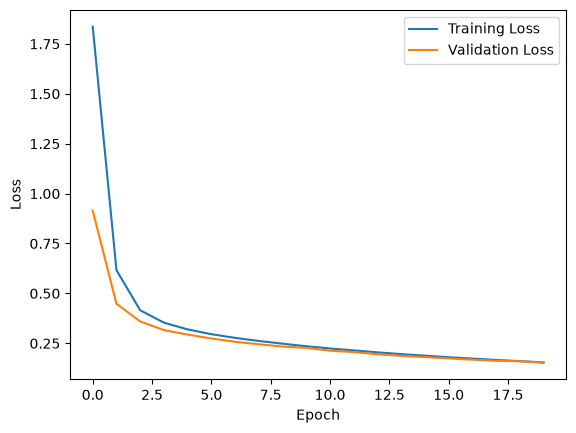

In [54]:
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

## Final Model Evaluation on Test Data

In [55]:
# Get predictions

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for digits, labels in test_loader:
        outputs = model(digits)

        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.tolist())
        all_predictions.extend(predictions.tolist())

In [56]:
# Calculate Accuracy, Precision, Recall, F1

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average="macro")
recall = recall_score(all_labels, all_predictions, average="macro")
f1 = f1_score(all_labels, all_predictions, average="macro")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Accuracy : 0.9551
Precision: 0.9551502121231842
Recall   : 0.9543815001421843
F1-Score : 0.9546438149676669
